# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Bima Satriawan | 5054251031 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score
import warnings
warnings.filterwarnings('ignore')


torch.manual_seed(42)
np.random.seed(42)

In [3]:
# Load dataset
path = '/kaggle/input/datasets/shrutimechlearn/churn-modelling/Churn_Modelling.csv'
df = pd.read_csv(path)

display(df.head())

print("Jumlah baris dan kolom:", df.shape)
print("Tipe data:\n", df.dtypes)
print("Statistik deskriptif:\n", df.describe())
print("Jumlah missing value:\n", df.isnull().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Jumlah baris dan kolom: (10000, 14)
Tipe data:
 RowNumber            int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object
Statistik deskriptif:
          RowNumber    CustomerId   CreditScore           Age        Tenure  \
count  10000.00000  1.000000e+04  10000.000000  10000.000000  10000.000000   
mean    5000.50000  1.569094e+07    650.528800     38.921800      5.012800   
std     2886.89568  7.193619e+04     96.653299     10.487806      2.892174   
min        1.00000  1.556570e+07    350.000000     18.000000      0.000000   
25%     2500.75000  1.562853e+07    584.000000     32.000000      3.000000   
50%     5000.50000  1.569074e+07    652.000000     37.000000      5.0

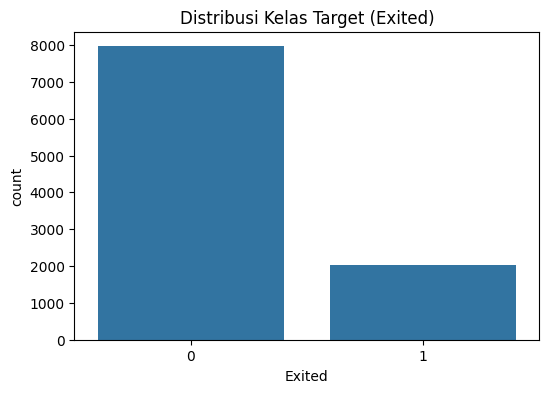

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Exited')
plt.title('Distribusi Kelas Target (Exited)')
plt.show()

print(df['Exited'].value_counts(normalize=True) * 100)

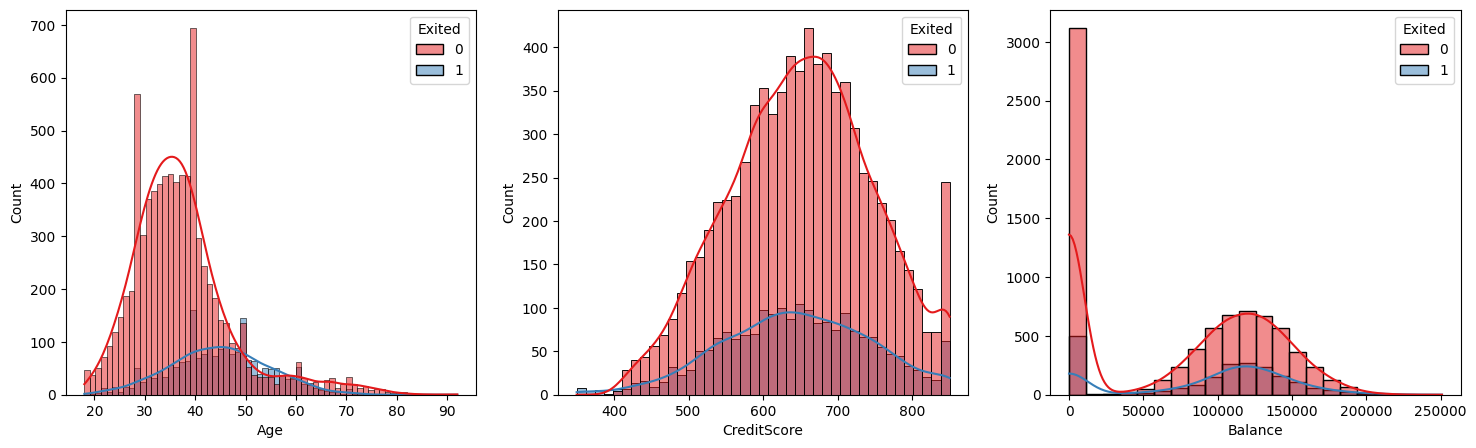

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(data=df, x='Age', hue='Exited', kde=True, ax=axes[0], palette='Set1')
sns.histplot(data=df, x='CreditScore', hue='Exited', kde=True, ax=axes[1], palette='Set1')
sns.histplot(data=df, x='Balance', hue='Exited', kde=True, ax=axes[2], palette='Set1')
plt.show()

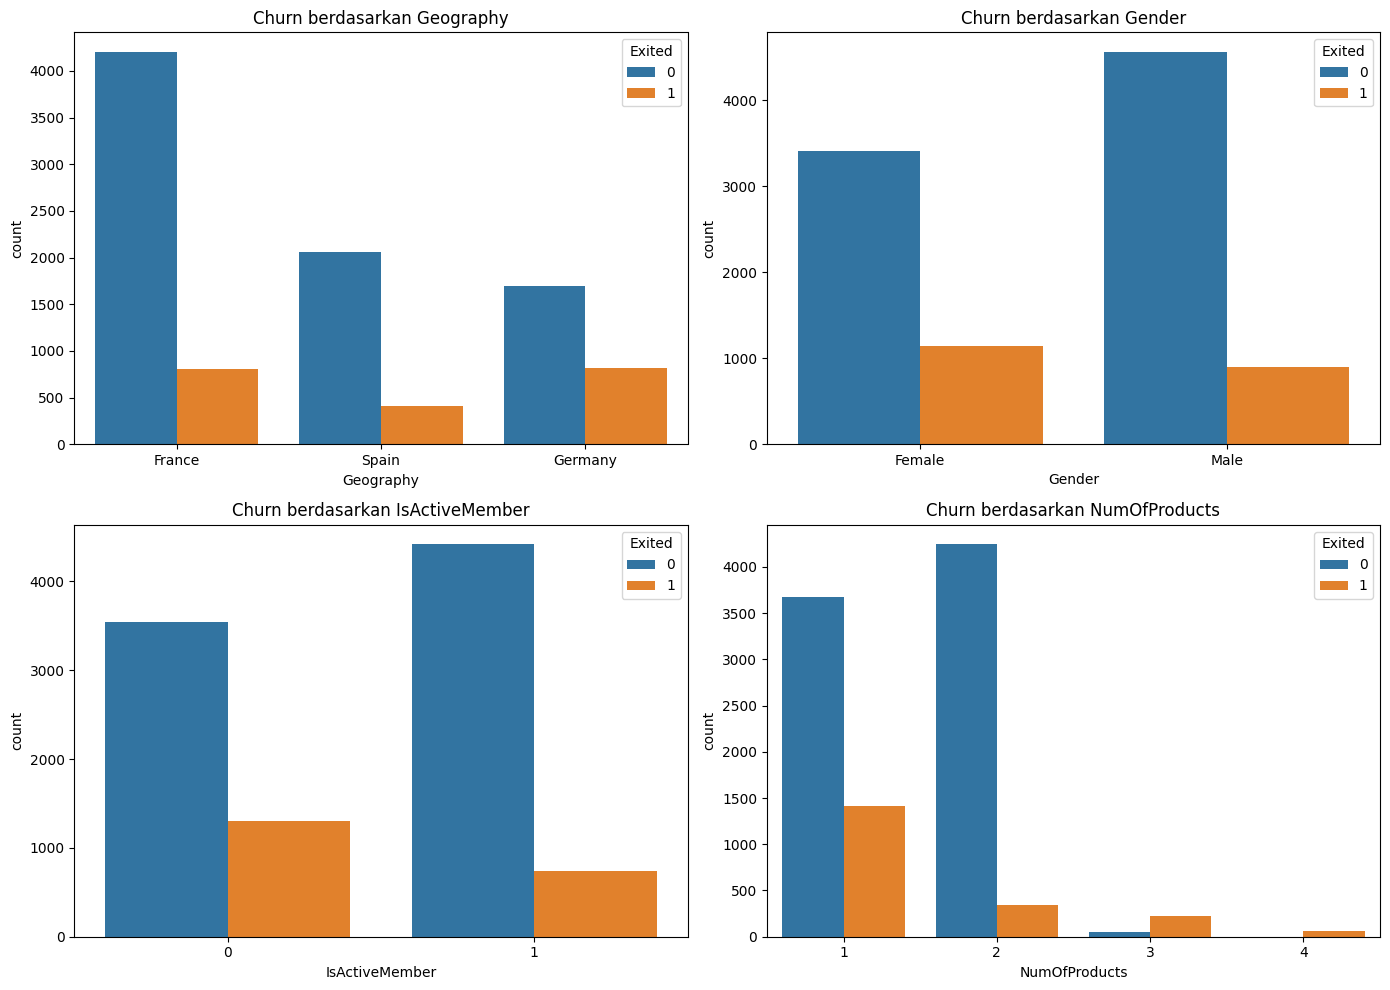

In [6]:
cat_cols = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, col in enumerate(cat_cols):
    ax = axes[i // 2, i % 2]
    sns.countplot(data=df, x=col, hue='Exited', ax=ax)
    ax.set_title(f'Churn berdasarkan {col}')
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Berdasarkan visualisasi di atas, kita dapat mengamati:
1. Dataset tidak seimbang (imbalanced). Nasabah yang tidak churn (0) jauh lebih banyak dibandingkan yang churn (1).
2. Nasabah dengan usia lebih tua (Age) dan saldo (Balance) yang tinggi cenderung lebih sering churn.
3. Nasabah dari Jerman (Germany) memiliki tingkat churn yang lebih tinggi dibandingkan Prancis dan Spanyol.
4. Nasabah yang tidak aktif (IsActiveMember = 0) dan memiliki jumlah produk (NumOfProducts) 3 atau 4 memiliki kecenderungan churn yang sangat tinggi.
5. Fitur RowNumber, CustomerId, dan Surname tidak memiliki korelasi terhadap target karena hanya berupa identitas.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [7]:
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

In [8]:
X = df.drop('Exited', axis=1)
y = df['Exited']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [9]:
cat_features = ['Geography', 'Gender']
num_features = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first'), cat_features)
    ])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [10]:
# Ubah ke dalam bentuk tensor float32
X_train_t = torch.tensor(X_train_processed, dtype=torch.float32)
X_val_t = torch.tensor(X_val_processed, dtype=torch.float32)
X_test_t = torch.tensor(X_test_processed, dtype=torch.float32)

y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

# Buat DataLoader untuk train set
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# DataLoader untuk validation dan test
val_dataset = TensorDataset(X_val_t, y_val_t)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

test_dataset = TensorDataset(X_test_t, y_test_t)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [11]:
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_processed, y_train)

y_pred_lr = log_reg.predict(X_test_processed)
y_prob_lr = log_reg.predict_proba(X_test_processed)[:, 1]

## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [12]:
class SimpleANN(nn.Module):
    def __init__(self, input_dim):
        super(SimpleANN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
    
    def forward(self, x):
        return self.net(x)

input_dim = X_train_t.shape[1]
simple_ann = SimpleANN(input_dim)
print(simple_ann)
print("Jumlah parameter:", sum(p.numel() for p in simple_ann.parameters()))

SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 209


In [13]:
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=30):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0
        
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * X_batch.size(0)
            preds = torch.sigmoid(outputs) >= 0.5
            train_correct += (preds == y_batch).sum().item()
            train_total += y_batch.size(0)
            
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)
                
                val_loss += loss.item() * X_batch.size(0)
                preds = torch.sigmoid(outputs) >= 0.5
                val_correct += (preds == y_batch).sum().item()
                val_total += y_batch.size(0)
                
        history['train_loss'].append(train_loss / train_total)
        history['val_loss'].append(val_loss / val_total)
        history['train_acc'].append(train_correct / train_total)
        history['val_acc'].append(val_correct / val_total)
        
    return history

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(simple_ann.parameters(), lr=0.001)
epochs = 30

history_simple = train_model(simple_ann, train_loader, val_loader, criterion, optimizer, epochs)

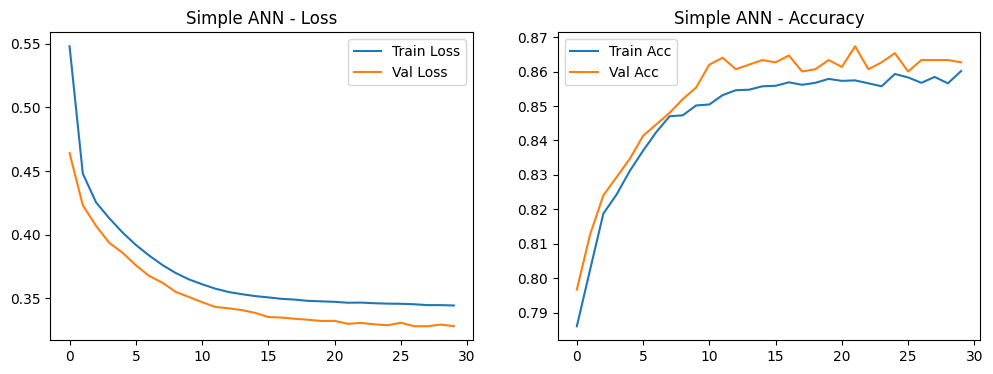

In [14]:
def plot_history(history, title):
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title(f'{title} - Loss')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history['train_acc'], label='Train Acc')
    plt.plot(history['val_acc'], label='Val Acc')
    plt.title(f'{title} - Accuracy')
    plt.legend()
    
    plt.show()

plot_history(history_simple, 'Simple ANN')

In [15]:
simple_ann.eval()
with torch.no_grad():
    logits_simple = simple_ann(X_test_t)
    y_prob_simple = torch.sigmoid(logits_simple).numpy().flatten()
    y_pred_simple = (y_prob_simple >= 0.5).astype(int)

## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [16]:
class DeepANN(nn.Module):
    def __init__(self, input_dim):
        super(DeepANN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(16, 1)
        )
        
    def forward(self, x):
        return self.net(x)

deep_ann = DeepANN(input_dim)
print(deep_ann)
print("Jumlah parameter:", sum(p.numel() for p in deep_ann.parameters()))

DeepANN(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 929


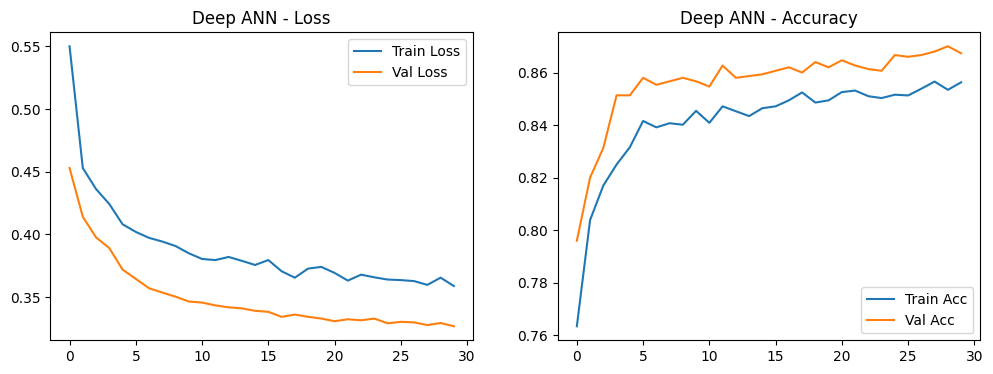

In [17]:
optimizer_deep = optim.Adam(deep_ann.parameters(), lr=0.001)
history_deep = train_model(deep_ann, train_loader, val_loader, criterion, optimizer_deep, epochs)

plot_history(history_deep, 'Deep ANN')

In [18]:
deep_ann.eval()
with torch.no_grad():
    logits_deep = deep_ann(X_test_t)
    y_prob_deep = torch.sigmoid(logits_deep).numpy().flatten()
    y_pred_deep = (y_prob_deep >= 0.5).astype(int)

## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [19]:
num_neg = (y_train == 0).sum()
num_pos = (y_train == 1).sum()
pos_weight = torch.tensor([num_neg / num_pos], dtype=torch.float32)

weighted_ann = DeepANN(input_dim)

criterion_weighted = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer_weighted = optim.Adam(weighted_ann.parameters(), lr=0.001)

history_weighted = train_model(weighted_ann, train_loader, val_loader, criterion_weighted, optimizer_weighted, epochs)

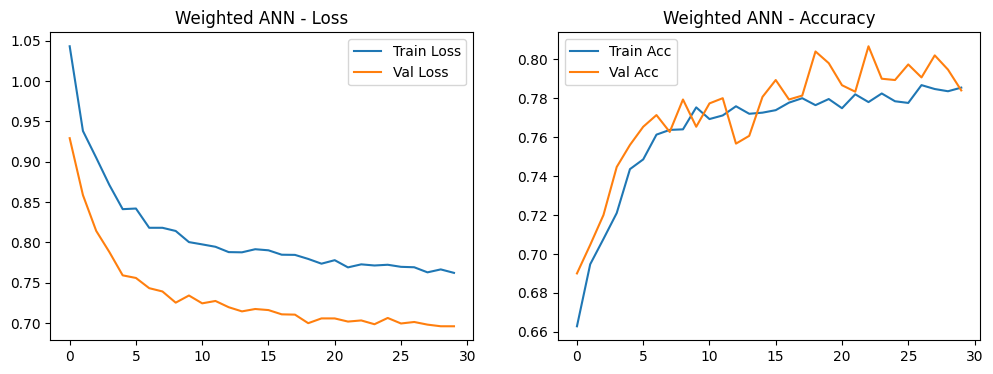

In [20]:
plot_history(history_weighted, 'Weighted ANN')

weighted_ann.eval()
with torch.no_grad():
    logits_weighted = weighted_ann(X_test_t)
    y_prob_weighted = torch.sigmoid(logits_weighted).numpy().flatten()
    y_pred_weighted = (y_prob_weighted >= 0.5).astype(int)

# 4. Evaluasi Model

In [21]:
models = {
    'Logistic Regression': y_pred_lr,
    'Simple ANN': y_pred_simple,
    'Deep ANN (Dropout)': y_pred_deep,
    'Weighted ANN': y_pred_weighted
}

metrics = []
for name, pred in models.items():
    metrics.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred)
    })

metrics_df = pd.DataFrame(metrics)
display(metrics_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.815333,0.645833,0.203279,0.309227
1,Simple ANN,0.866000,0.795455,0.459016,0.582121
2,Deep ANN (Dropout),0.870667,0.817143,0.468852,0.595833
3,Weighted ANN,0.781333,0.476768,0.773770,0.590000


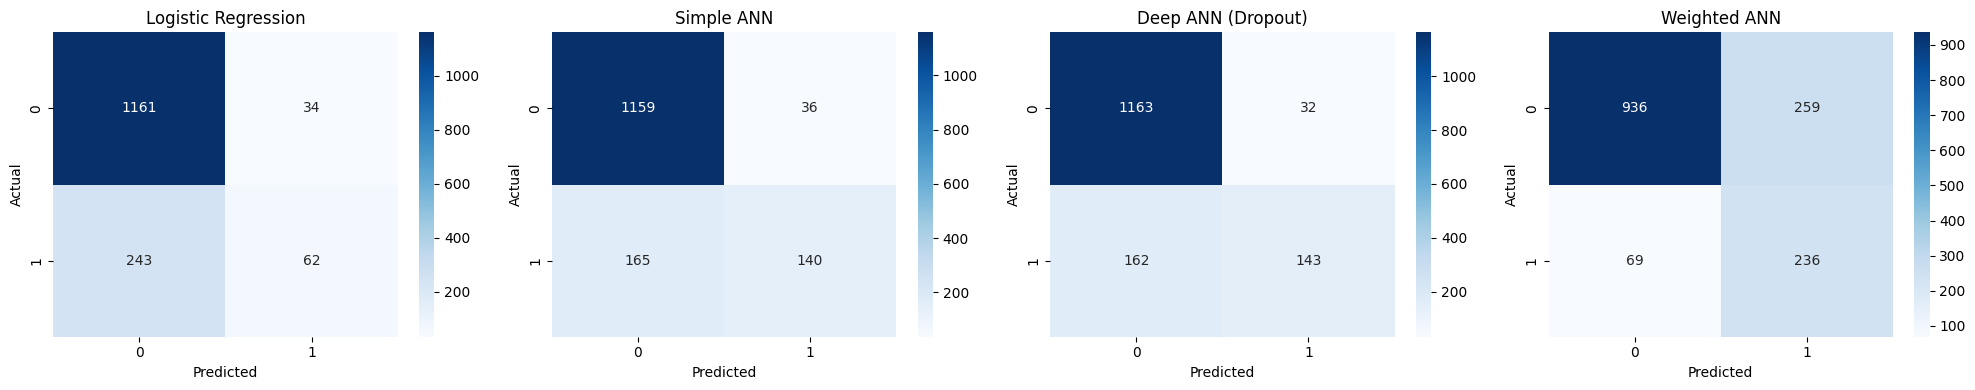

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, pred) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

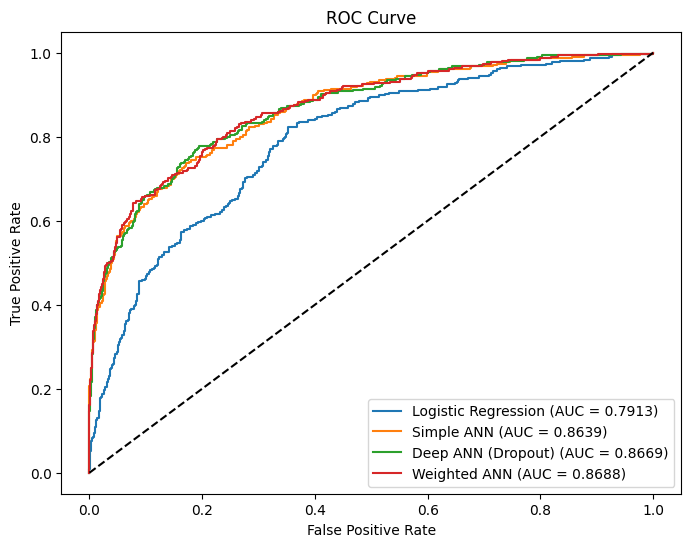

In [23]:
# ROC Curve dan AUC
plt.figure(figsize=(8, 6))
probabilities = {
    'Logistic Regression': y_prob_lr,
    'Simple ANN': y_prob_simple,
    'Deep ANN (Dropout)': y_prob_deep,
    'Weighted ANN': y_prob_weighted
}

for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Berdasarkan hasil eksperimen, dataset Churn Modelling memiliki tingkat ketidakseimbangan kelas (imbalanced) yang cukup signifikan. Hal ini membuat metrik accuracy saja tidak cukup, sehingga perlu melihat Precision, Recall, dan F1-Score.

1. Baseline Logistic Regression: Model ini memberikan performa yang cukup solid dengan akurasi yang baik. Namun, karena dataset imbalanced, recall untuk kelas churn (kelas 1) biasanya relatif rendah. Model ini lebih banyak memprediksi kelas mayoritas.
2. Simple ANN: Model dengan satu hidden layer ini memiliki performa yang mirip dengan Logistic Regression. Dari learning curve, terlihat bahwa model ini cukup cepat mencapai konvergensi, tetapi rentan mengalami overfitting karena tidak adanya regularisasi. Gap antara loss train dan validation mulai melebar di akhir epoch.
3. Deep ANN dengan Dropout: Penambahan hidden layer dan Dropout berhasil membuat learning curve lebih stabil. Gap antara train dan validation loss lebih kecil dibandingkan Simple ANN, menunjukkan bahwa Dropout efektif menekan overfitting. Namun, penambahan kompleksitas ini tidak serta merta menaikkan recall secara drastis jika tidak diimbangi dengan penanganan imbalanced data.
4. Weighted ANN: Penggunaan class weight (pos_weight) pada loss function memberikan dampak yang sangat besar pada nilai Recall untuk kelas churn. Model ini jauh lebih agresif dalam memprediksi churn, sehingga Recall naik drastis. Konsekuensinya, Precision menurun karena banyak nasabah yang sebenarnya tidak churn (False Positive) ikut terprediksi sebagai churn.

Secara keseluruhan, model terbaik bergantung pada tujuan bisnis. Jika perusahaan ingin menangkap sebanyak mungkin nasabah yang berpotensi churn (minimalkan False Negative), maka Weighted ANN adalah pilihan terbaik. Namun, jika ingin menghindari biaya promosi yang sia-sia akibat False Positive, Deep ANN atau Logistic Regression bisa lebih seimbang.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Kesimpulan:
1. Model Artificial Neural Network (ANN) berhasil diimplementasikan untuk memprediksi customer churn menggunakan PyTorch dan mampu bersaing dengan baseline Logistic Regression.
2. Penanganan data imbalanced sangat krusial. Penggunaan class weight (pos_weight) pada fungsi loss terbukti efektif untuk meningkatkan sensitivitas model dalam mendeteksi kelas minoritas (churn), yang ditunjukkan dengan naiknya nilai Recall secara signifikan.
3. Arsitektur yang lebih dalam dengan Dropout membantu mengurangi overfitting, terlihat dari learning curve yang lebih stabil dan jarak antara train loss dan validation loss yang lebih kecil.

Saran:
Eksplorasi teknik penanganan imbalanced data lainnya seperti SMOTE atau Random Undersampling untuk melihat apakah hasilnya lebih baik dibandingkan class weight.